<a href="https://colab.research.google.com/github/rahulbera851-cell/CodeAlpha_UnemploymentAnalysi/blob/main/Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

Upload your CarDekho CSV dataset


Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO.csv

Dataset loaded successfully!

First 5 Rows:
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  

Dataset Shape:
(4340, 8)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Ra

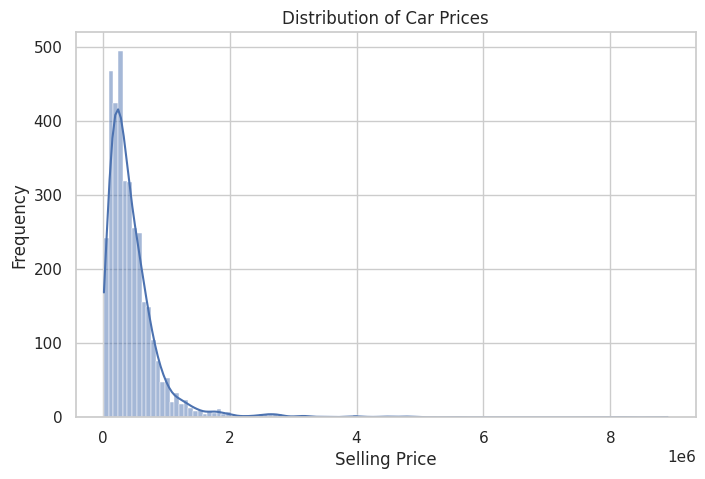

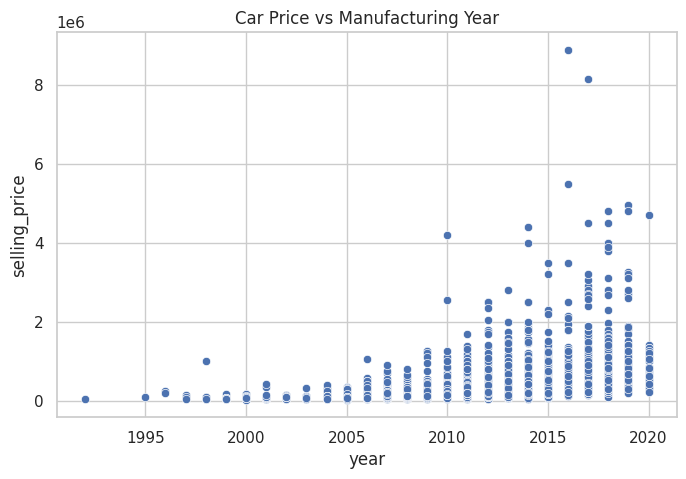

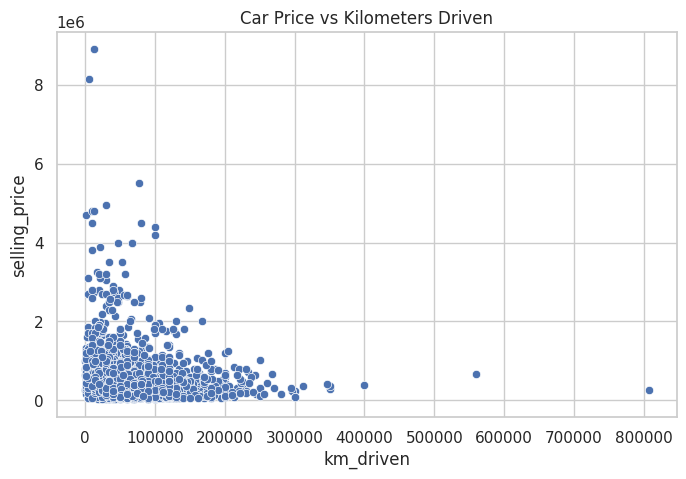

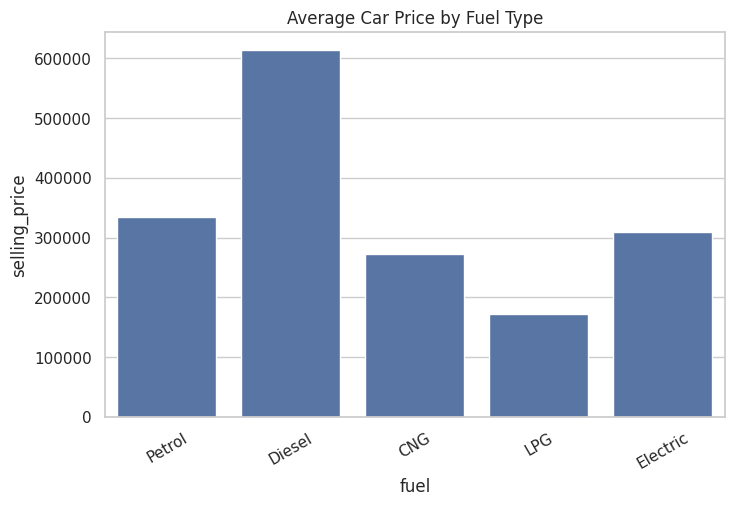


Numerical Features:
['km_driven', 'car_age']

Categorical Features:
['fuel', 'seller_type', 'transmission', 'owner', 'brand']

Training Records: 2861
Testing Records: 716

 Linear Regression
MAE: 179642.87
MSE: 148011520115.04
RMSE: 384722.65
R2 Score: 0.5405

 Random Forest
MAE: 156570.8
MSE: 129575959298.6
RMSE: 359966.61
R2 Score: 0.5978

MODEL COMPARISON:
            Model           MAE          MSE          RMSE  R2 Score
Linear Regression 179642.867728 1.480115e+11 384722.653499  0.540527
    Random Forest 156570.802297 1.295760e+11 359966.608588  0.597757

Best Model: Random Forest


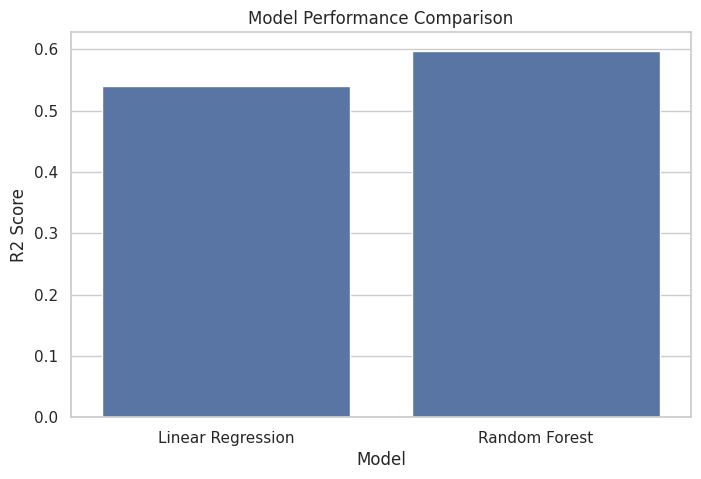

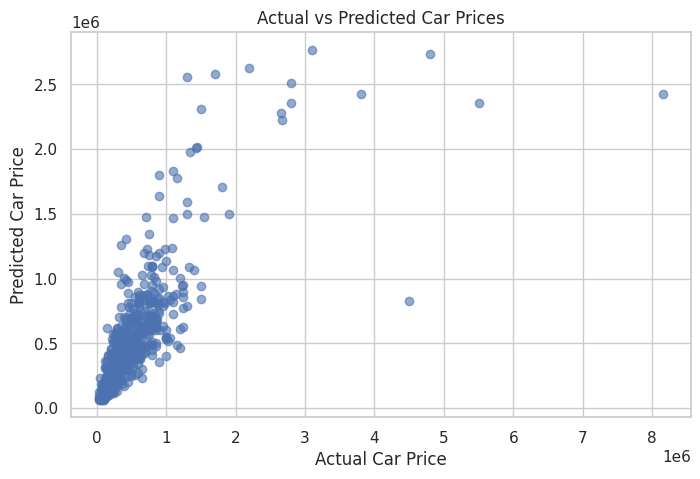

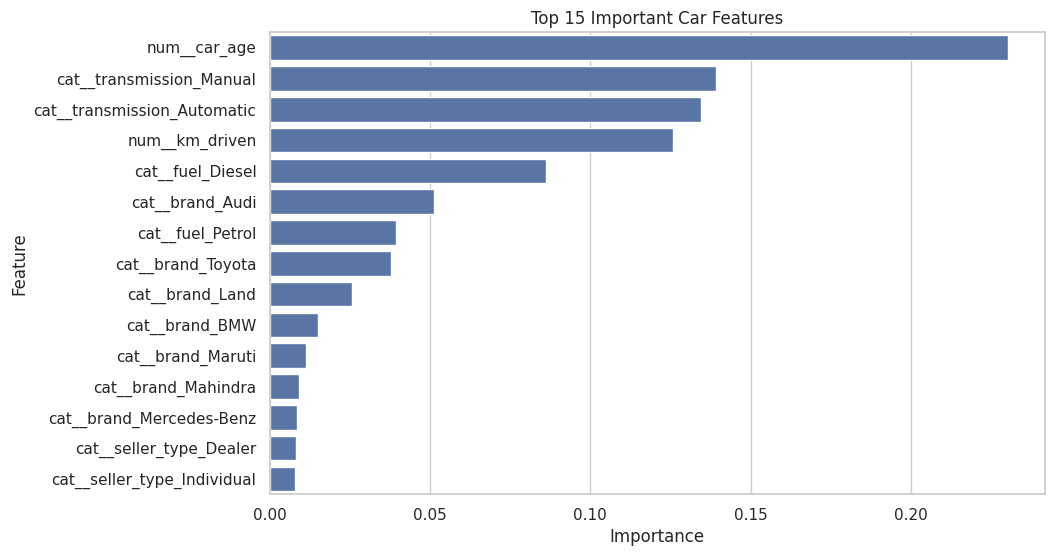


NEW CAR PRICE PREDICTION
Predicted Car Price: ₹ 456844.0

Cleaned dataset saved!
Machine Learning Model Saved!

Project completed successfully!



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL TASKS COMPLETED!


In [3]:

# ============================================================
# PROJECT: CAR PRICE PREDICTION USING MACHINE LEARNING
# Platform: Google Colab
# Dataset: Vehicle Dataset from CarDekho
# Algorithms: Linear Regression & Random Forest Regressor
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


# 2. UPLOAD DATASET

print("\nUpload your CarDekho CSV dataset")

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("\nDataset loaded successfully!")


# 3. DATASET INFORMATION

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))


# 4. DATA CLEANING

# Remove duplicate records

df.drop_duplicates(inplace=True)

# Remove extra spaces from column names

df.columns = df.columns.str.strip()

# Handle column name variations

df.columns = df.columns.str.lower()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates Removed Successfully!")


# 5. FEATURE ENGINEERING

# Extract car brand from car name

if "name" in df.columns:

    df["brand"] = df["name"].astype(str).apply(
        lambda x: x.split()[0]
    )

# Convert numerical columns

numeric_columns = [
    "year",
    "selling_price",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
]

for col in numeric_columns:

    if col in df.columns:

        df[col] = pd.to_numeric(
            df[col].astype(str).str.extract(
                r"([-+]?\d*\.?\d+)"
            )[0],
            errors="coerce"
        )

# Convert manufacturing year into car age

if "year" in df.columns:

    df["car_age"] = 2026 - df["year"]

# Remove invalid target values

if "selling_price" not in df.columns:
    raise ValueError(
        "Target column selling_price not found in dataset."
    )

df = df[
    df["selling_price"].notna() &
    (df["selling_price"] > 0)
]

print("\nFeature Engineering Completed!")


# 6. EXPLORATORY DATA ANALYSIS (EDA)

print("\nDataset after cleaning:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

# Car Price Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    df["selling_price"],
    kde=True
)

plt.title("Distribution of Car Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()


# Car Price vs Manufacturing Year

if "year" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x="year",
        y="selling_price"
    )

    plt.title("Car Price vs Manufacturing Year")
    plt.show()


# Car Price vs Kilometers Driven

if "km_driven" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x="km_driven",
        y="selling_price"
    )

    plt.title("Car Price vs Kilometers Driven")
    plt.show()


# Average Price by Fuel Type

if "fuel" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=df,
        x="fuel",
        y="selling_price",
        errorbar=None
    )

    plt.title("Average Car Price by Fuel Type")
    plt.xticks(rotation=30)
    plt.show()


# 7. PREPARE FEATURES AND TARGET

# Remove original year because car_age is available

features_to_remove = [
    "selling_price",
    "name",
    "year"
]

X = df.drop(
    columns=[
        col for col in features_to_remove
        if col in df.columns
    ]
)

y = df["selling_price"]

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# 8. DATA PREPROCESSING

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# 9. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


# 10. TRAIN LINEAR REGRESSION MODEL

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)


# 11. TRAIN RANDOM FOREST MODEL

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)


# 12. MODEL EVALUATION

def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    print("\n", name)

    print("MAE:", round(mae, 2))

    print("MSE:", round(mse, 2))

    print("RMSE:", round(rmse, 2))

    print("R2 Score:", round(r2, 4))

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)


# 13. COMPARE MODELS

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
print(results_df.to_string(index=False))

# Select model with highest R2 score

best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

if best_model_name == "Random Forest":
    best_model = random_forest_model
    best_predictions = rf_predictions
else:
    best_model = linear_model
    best_predictions = linear_predictions

print("\nBest Model:", best_model_name)


# 14. VISUALIZE MODEL COMPARISON

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Model Performance Comparison")
plt.ylabel("R2 Score")
plt.show()


# 15. ACTUAL VS PREDICTED PRICES

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()


# 16. FEATURE IMPORTANCE
# Available for Random Forest only

if best_model_name == "Random Forest":

    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importances = (
        best_model
        .named_steps["model"]
        .feature_importances_
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Car Features")

    plt.show()


# 17. PREDICT A NEW CAR PRICE

# Use an existing record as a template so all features
# and categories match the training dataset.

new_car = X.iloc[[0]].copy()

# Example changes to numerical features

for col, value in {
    "km_driven": 30000,
    "mileage": 20.0,
    "engine": 1200,
    "max_power": 85,
    "seats": 5,
    "car_age": 3
}.items():

    if col in new_car.columns:
        new_car.loc[new_car.index[0], col] = value

predicted_price = best_model.predict(new_car)[0]

print("\nNEW CAR PRICE PREDICTION")

print("Predicted Car Price: ₹",
      round(predicted_price, 2))


# 18. SAVE CLEANED DATASET

df.to_csv(
    "Cleaned_Car_Price_Data.csv",
    index=False
)

print("\nCleaned dataset saved!")


# 19. SAVE TRAINED MODEL

joblib.dump(
    best_model,
    "Car_Price_Prediction_Model.pkl"
)

print("Machine Learning Model Saved!")


# 20. DOWNLOAD PROJECT FILES

print("\nProject completed successfully!")

print("\nDownloading cleaned dataset...")

files.download("Cleaned_Car_Price_Data.csv")

print("\nDownloading trained model...")

files.download("Car_Price_Prediction_Model.pkl")

print("\nALL TASKS COMPLETED!")